# Sentiment Classification with TF-IDF, Multinomial Naive Bayes and Logistic Regression
An NLP pipeline that cleans review text (lowercasing, HTML and punctuation removal, stopword removal, lemmatization), converts it to TF-IDF vectors (`max_features=5000`), trains `MultinomialNB` and `LogisticRegression`, benchmarks them, and exposes a `predict_sentiment()` helper for live phrases.

**Data note.** The uploaded `sentiment_reviews.csv` contains only 10 reviews (5 positive, 4 negative, 1 neutral), which is far too small to train or benchmark a classifier. The models are therefore trained and benchmarked on the 2,000-review NLTK Movie Reviews corpus (1,000 positive and 1,000 negative), and the uploaded product reviews are used as a small out-of-domain check in section 10.

## 1. Imports and configuration

In [1]:
import re
import warnings
warnings.filterwarnings("ignore")
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, confusion_matrix, classification_report
)

for resource in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.4f}".format

## 2. Load the data

In [2]:
MOVIE_CSV = Path("movie_reviews.csv")

if not MOVIE_CSV.exists():
    nltk.download("movie_reviews", quiet=True)
    from nltk.corpus import movie_reviews
    corpus = pd.DataFrame({
        "review_text": [movie_reviews.raw(f) for f in movie_reviews.fileids()],
        "sentiment": [movie_reviews.categories(f)[0] for f in movie_reviews.fileids()],
    })
    corpus["sentiment"] = corpus["sentiment"].map({"pos": "positive", "neg": "negative"})
    corpus.to_csv(MOVIE_CSV, index=False)

df = pd.read_csv(MOVIE_CSV)
print(f"Movie reviews: {df.shape}")
print(df["sentiment"].value_counts().to_string())
df.head()

Movie reviews: (2000, 2)
sentiment
negative    1000
positive    1000


,review_text,sentiment
0,"plot : two teen couples go to a church party ,...",negative
1,the happy bastard's quick movie review \ndamn ...,negative
2,it is movies like these that make a jaded movi...,negative
3,""" quest for camelot "" is warner bros . ' firs...",negative
4,synopsis : a mentally unstable man undergoing ...,negative


In [3]:
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate review texts:", int(df["review_text"].duplicated().sum()))

df["word_count"] = df["review_text"].str.split().str.len()
df["label"] = (df["sentiment"] == "positive").astype(int)
df.groupby("sentiment")["word_count"].describe()

Missing values: 0
Duplicate review texts: 0


,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,"1,000.0000",705.6300,296.7298,17.0000,510.0000,668.5000,848.2500,"2,181.0000"
positive,"1,000.0000",787.0510,352.7999,130.0000,543.5000,731.5000,957.2500,"2,678.0000"


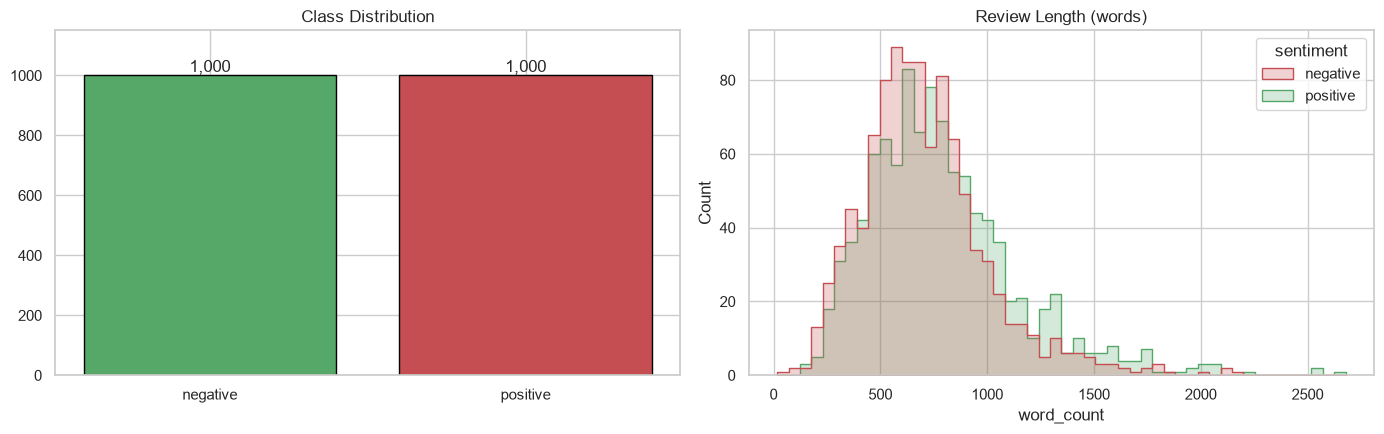

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

counts = df["sentiment"].value_counts()
axes[0].bar(counts.index, counts.values, color=["#55A868", "#C44E52"], edgecolor="black")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")
axes[0].set_title("Class Distribution")
axes[0].set_ylim(0, counts.max() * 1.15)

sns.histplot(data=df, x="word_count", hue="sentiment", bins=50, element="step",
             palette={"positive": "#55A868", "negative": "#C44E52"}, ax=axes[1])
axes[1].set_title("Review Length (words)")

plt.tight_layout()
plt.show()

## 3. Text preprocessing
Cleaning steps: lowercase, strip HTML tags and URLs, expand contractions, drop everything except letters, tokenize on whitespace, remove stopwords, and lemmatize (each token is reduced as a verb, then as a noun, so `movies` becomes `movie` and `running` becomes `run`).

The default NLTK stopword list contains negations such as `not` and `no`. Removing them turns `not good` into `good`, which reverses the sentiment. Two stopword settings are therefore compared later: the full NLTK list, and the same list with negations (and the intensifiers `very` and `too`) kept.

In [5]:
lemmatizer = WordNetLemmatizer()

NLTK_STOPWORDS = set(stopwords.words("english"))
KEEP_WORDS = {"no", "nor", "not", "never", "very", "too"}
NEGATION_SAFE_STOPWORDS = NLTK_STOPWORDS - KEEP_WORDS

CONTRACTIONS = [
    (r"\bwon't\b", "will not"),
    (r"\bcan't\b", "can not"),
    (r"n't\b", " not"),
    (r"'re\b", " are"),
    (r"'ve\b", " have"),
    (r"'ll\b", " will"),
    (r"'m\b", " am"),
]


def clean_text(text, stop_words=NEGATION_SAFE_STOPWORDS, lemmatize=True):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    for pattern, replacement in CONTRACTIONS:
        text = re.sub(pattern, replacement, text)
    tokens = re.findall(r"[a-z]+", text)
    tokens = [t for t in tokens if len(t) > 1 and t not in stop_words]
    if lemmatize:
        tokens = [lemmatizer.lemmatize(lemmatizer.lemmatize(t, "v"), "n") for t in tokens]
    return " ".join(tokens)


sample = "<br />I didn't like it. The movies were boring & the actors couldn't act!"
print("Original:       ", sample)
print("Negations kept: ", clean_text(sample))
print("NLTK default:   ", clean_text(sample, stop_words=NLTK_STOPWORDS))

Original:        <br />I didn't like it. The movies were boring & the actors couldn't act!
Negations kept:  not like movie bore actor could not act
NLTK default:    like movie bore actor could act


In [6]:
df["text_raw"] = df["review_text"]
df["text_default"] = df["review_text"].map(lambda t: clean_text(t, stop_words=NLTK_STOPWORDS))
df["text_clean"] = df["review_text"].map(clean_text)

df.loc[:2, ["review_text", "text_clean"]].assign(review_text=lambda d: d["review_text"].str[:150], text_clean=lambda d: d["text_clean"].str[:150])

,review_text,text_clean
0,"plot : two teen couples go to a church party ,...",plot two teen couple go church party drink dri...
1,the happy bastard's quick movie review \ndamn ...,happy bastard quick movie review damn bug get ...
2,it is movies like these that make a jaded movi...,movie like make jade movie viewer thankful inv...


In [7]:
avg_before = df["review_text"].str.split().str.len().mean()
avg_after = df["text_clean"].str.split().str.len().mean()
vocab_before = len({w for t in df["review_text"].str.lower() for w in re.findall(r"[a-z]+", t)})
vocab_after = len({w for t in df["text_clean"] for w in t.split()})

pd.DataFrame({
    "average tokens per review": [avg_before, avg_after],
    "vocabulary size": [vocab_before, vocab_after],
}, index=["before cleaning", "after cleaning"])

,average tokens per review,vocabulary size
before cleaning,746.3405,38911
after cleaning,359.5555,29108


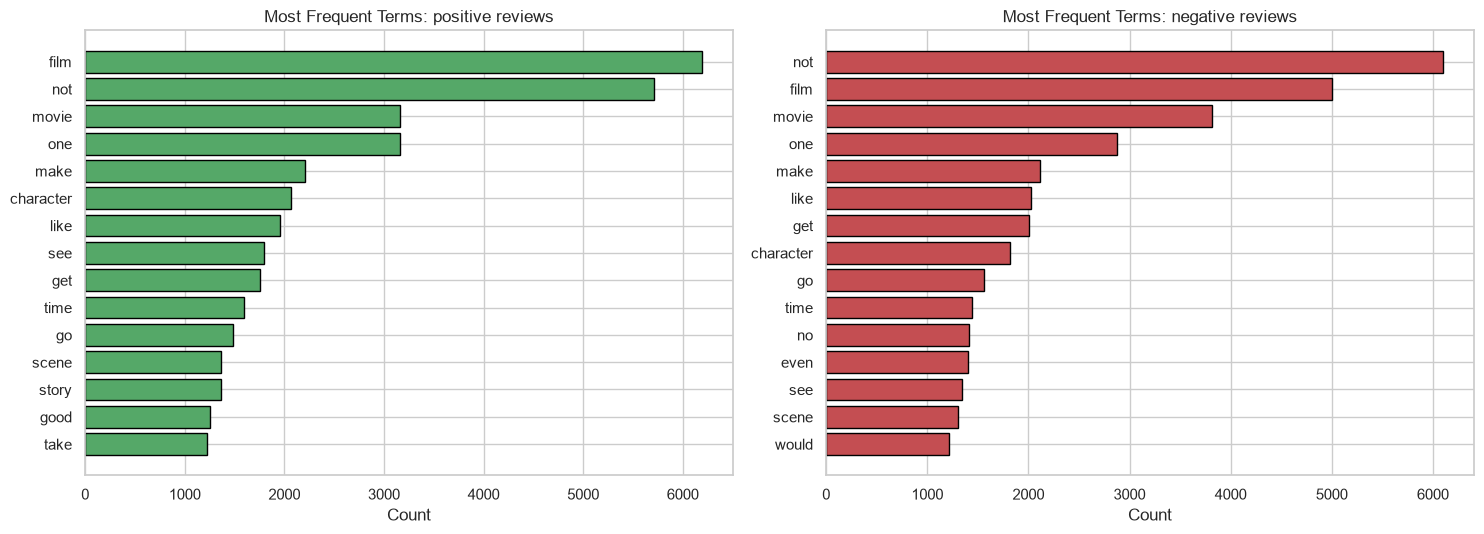

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (label, color) in zip(axes, [("positive", "#55A868"), ("negative", "#C44E52")]):
    tokens = Counter(" ".join(df.loc[df["sentiment"] == label, "text_clean"]).split())
    top = pd.Series(dict(tokens.most_common(15))).iloc[::-1]
    ax.barh(top.index, top.values, color=color, edgecolor="black")
    ax.set_title(f"Most Frequent Terms: {label} reviews")
    ax.set_xlabel("Count")
plt.tight_layout()
plt.show()

## 4. Train/test split
The split is stratified. Cleaning is stateless (it learns nothing from the data), so it is applied once to every review; the TF-IDF vocabulary and IDF weights are learned inside the pipeline on training data only.

In [9]:
train_idx, test_idx = train_test_split(
    df.index, test_size=0.20, stratify=df["label"], random_state=RANDOM_STATE
)

y_train, y_test = df.loc[train_idx, "label"], df.loc[test_idx, "label"]
X_train, X_test = df.loc[train_idx, "text_clean"], df.loc[test_idx, "text_clean"]

print(f"Train: {len(train_idx):,} | Test: {len(test_idx):,}")
print(f"Positive share  train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")

Train: 1,600 | Test: 400
Positive share  train: 0.500 | test: 0.500


## 5. Effect of preprocessing choices (cross-validation)
Four setups are compared with 5-fold stratified cross-validation on the training set only, using default model settings. Every setup uses `TfidfVectorizer(max_features=5000)`.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

variants = {
    "Raw text, no cleaning": ("text_raw", dict()),
    "Cleaned, NLTK stopwords (negations removed)": ("text_default", dict()),
    "Cleaned, negations kept (main setup)": ("text_clean", dict()),
    "Cleaned, negations kept + bigrams": ("text_clean", dict(ngram_range=(1, 2))),
}


def make_pipeline(classifier, **tfidf_kwargs):
    return Pipeline([
        ("tfidf", TfidfVectorizer(max_features=5000, **tfidf_kwargs)),
        ("clf", classifier),
    ])


rows = []
for name, (column, tfidf_kwargs) in variants.items():
    row = {"Setup": name}
    for model_name, classifier in [("Naive Bayes", MultinomialNB()), ("Logistic Regression", LogisticRegression(max_iter=2000))]:
        scores = cross_val_score(make_pipeline(classifier, **tfidf_kwargs), df.loc[train_idx, column], y_train, cv=cv, scoring="accuracy")
        row[f"{model_name} CV accuracy"] = f"{scores.mean():.4f} ± {scores.std():.4f}"
    rows.append(row)

pd.DataFrame(rows).set_index("Setup")

,Naive Bayes CV accuracy,Logistic Regression CV accuracy
Setup,,
"Raw text, no cleaning",0.8125 ± 0.0190,0.8219 ± 0.0182
"Cleaned, NLTK stopwords (negations removed)",0.8244 ± 0.0174,0.8450 ± 0.0118
"Cleaned, negations kept (main setup)",0.8256 ± 0.0172,0.8425 ± 0.0131
"Cleaned, negations kept + bigrams",0.8325 ± 0.0088,0.8456 ± 0.0102


This table is a diagnostic. The main setup (negations kept, unigrams) follows the specified pipeline and is used for everything below.

## 6. Hyperparameter tuning
The Naive Bayes smoothing parameter `alpha` and the Logistic Regression regularization strength `C` are tuned with 5-fold cross-validation on the training set.

In [11]:
nb_search = GridSearchCV(
    make_pipeline(MultinomialNB()),
    {"clf__alpha": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]},
    cv=cv, scoring="accuracy", n_jobs=-1,
).fit(X_train, y_train)

lr_search = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    {"clf__C": [0.1, 0.3, 1, 3, 10, 30, 100]},
    cv=cv, scoring="accuracy", n_jobs=-1,
).fit(X_train, y_train)

print(f"Naive Bayes          best alpha = {nb_search.best_params_['clf__alpha']} | CV accuracy = {nb_search.best_score_:.4f}")
print(f"Logistic Regression  best C     = {lr_search.best_params_['clf__C']} | CV accuracy = {lr_search.best_score_:.4f}")

Naive Bayes          best alpha = 1.0 | CV accuracy = 0.8256
Logistic Regression  best C     = 3 | CV accuracy = 0.8519


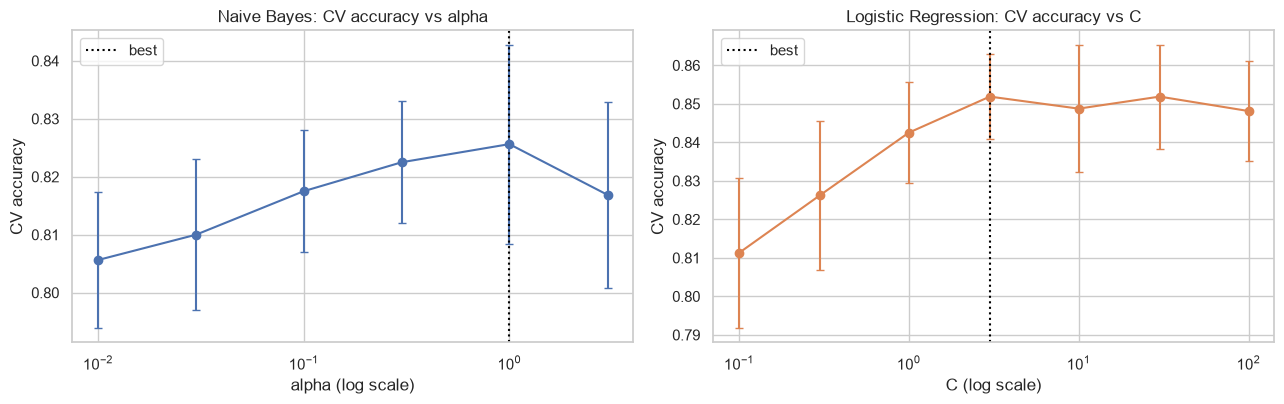

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, search, param, title, color in [
    (axes[0], nb_search, "clf__alpha", "Naive Bayes: CV accuracy vs alpha", "#4C72B0"),
    (axes[1], lr_search, "clf__C", "Logistic Regression: CV accuracy vs C", "#DD8452"),
]:
    res = pd.DataFrame(search.cv_results_)
    ax.errorbar(res[f"param_{param}"].astype(float), res["mean_test_score"], yerr=res["std_test_score"],
                marker="o", color=color, capsize=3)
    ax.set_xscale("log")
    ax.axvline(search.best_params_[param], color="black", linestyle=":", label="best")
    ax.set_title(title)
    ax.set_xlabel(param.replace("clf__", "") + " (log scale)")
    ax.set_ylabel("CV accuracy")
    ax.legend()
plt.tight_layout()
plt.show()

In [13]:
models = {
    "Naive Bayes": nb_search.best_estimator_,
    "Logistic Regression": lr_search.best_estimator_,
}

## 7. Test-set benchmark

In [14]:
class_names = ["negative", "positive"]
predictions = {name: model.predict(X_test) for name, model in models.items()}
probabilities = {name: model.predict_proba(X_test)[:, 1] for name, model in models.items()}

benchmark = pd.DataFrame({
    name: {
        "Accuracy": accuracy_score(y_test, predictions[name]),
        "Precision": precision_score(y_test, predictions[name]),
        "Recall": recall_score(y_test, predictions[name]),
        "F1-score": f1_score(y_test, predictions[name]),
        "ROC-AUC": roc_auc_score(y_test, probabilities[name]),
    } for name in models
}).T
benchmark["CV accuracy"] = [nb_search.best_score_, lr_search.best_score_]
benchmark

,Accuracy,Precision,Recall,F1-score,ROC-AUC,CV accuracy
Naive Bayes,0.8050,0.8245,0.7750,0.7990,0.8924,0.8256
Logistic Regression,0.8450,0.8194,0.8850,0.8510,0.9246,0.8519


In [15]:
for name in models:
    print("=" * 58)
    print(name)
    print("=" * 58)
    print(classification_report(y_test, predictions[name], target_names=class_names, digits=3))

Naive Bayes
              precision    recall  f1-score   support

    negative      0.788     0.835     0.811       200
    positive      0.824     0.775     0.799       200

    accuracy                          0.805       400
   macro avg      0.806     0.805     0.805       400
weighted avg      0.806     0.805     0.805       400

Logistic Regression
              precision    recall  f1-score   support

    negative      0.875     0.805     0.839       200
    positive      0.819     0.885     0.851       200

    accuracy                          0.845       400
   macro avg      0.847     0.845     0.845       400
weighted avg      0.847     0.845     0.845       400



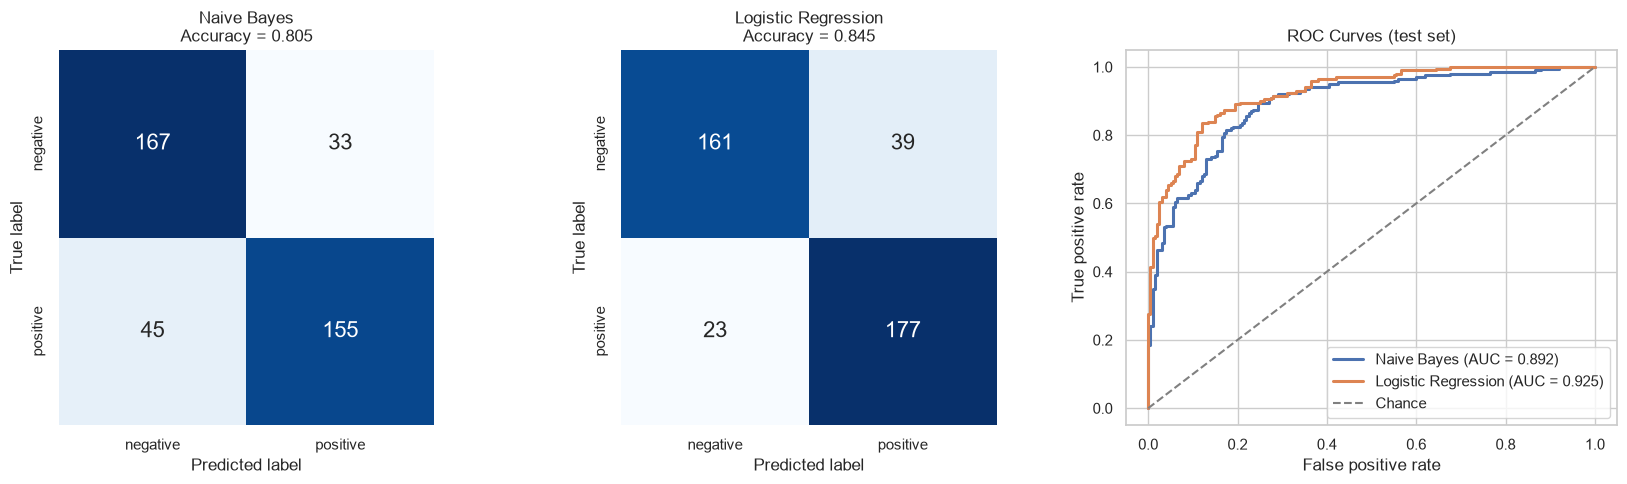

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, name in zip(axes[:2], models):
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
                xticklabels=class_names, yticklabels=class_names, annot_kws={"size": 16}, ax=ax)
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, predictions[name]):.3f}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

for name, color in zip(models, ["#4C72B0", "#DD8452"]):
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    axes[2].plot(fpr, tpr, color=color, linewidth=2.2, label=f"{name} (AUC = {roc_auc_score(y_test, probabilities[name]):.3f})")
axes[2].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Chance")
axes[2].set_title("ROC Curves (test set)")
axes[2].set_xlabel("False positive rate")
axes[2].set_ylabel("True positive rate")
axes[2].legend(loc="lower right")

plt.tight_layout()
plt.show()

## 8. What the models learned

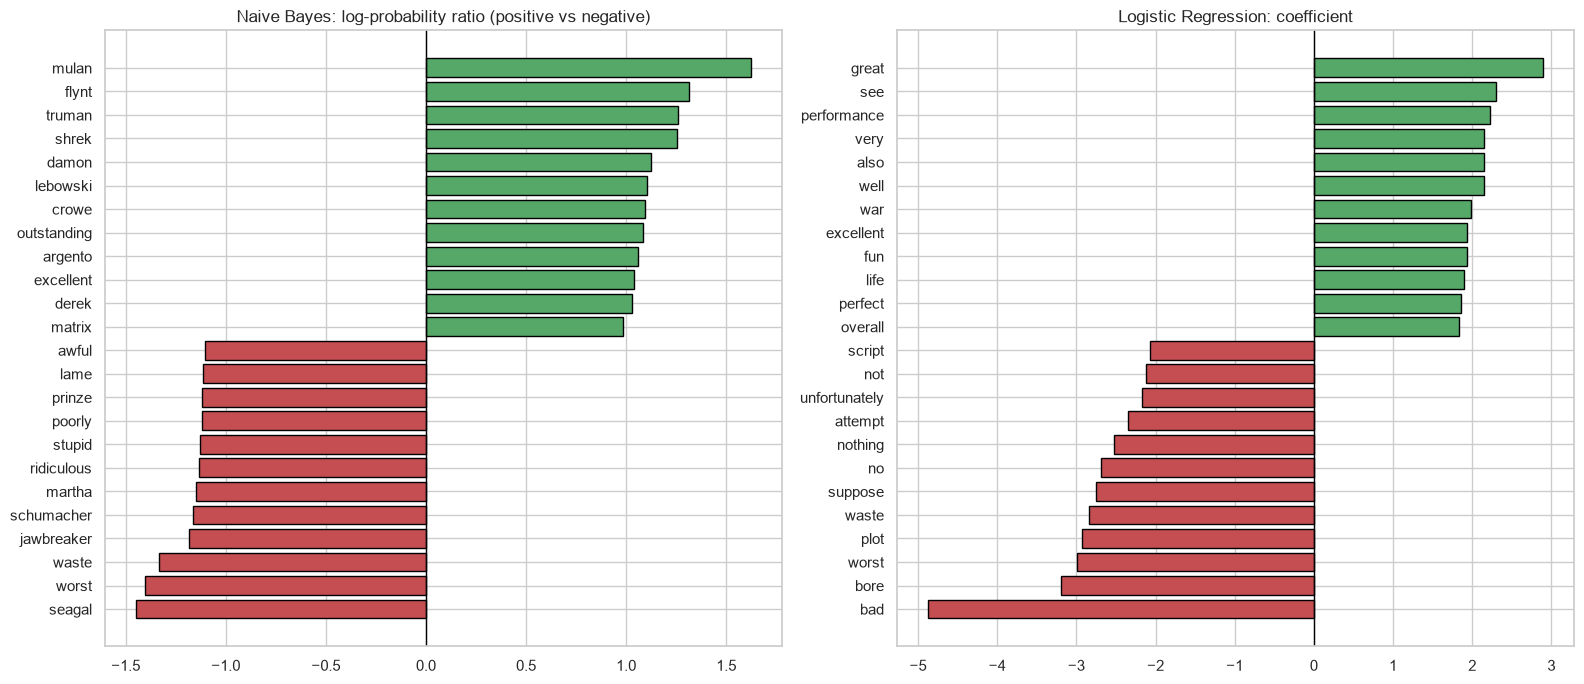

In [17]:
feature_names = np.array(models["Naive Bayes"].named_steps["tfidf"].get_feature_names_out())

nb_scores = models["Naive Bayes"].named_steps["clf"].feature_log_prob_
nb_signal = pd.Series(nb_scores[1] - nb_scores[0], index=feature_names)
lr_signal = pd.Series(models["Logistic Regression"].named_steps["clf"].coef_[0], index=feature_names)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, signal, title in [
    (axes[0], nb_signal, "Naive Bayes: log-probability ratio (positive vs negative)"),
    (axes[1], lr_signal, "Logistic Regression: coefficient"),
]:
    extremes = pd.concat([signal.nsmallest(12), signal.nlargest(12)]).sort_values()
    ax.barh(extremes.index, extremes.values, color=["#C44E52" if v < 0 else "#55A868" for v in extremes.values], edgecolor="black")
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [18]:
wrong = np.where(predictions["Logistic Regression"] != y_test.values)[0]
errors = df.loc[X_test.index[wrong]].assign(
    predicted=np.where(probabilities["Logistic Regression"][wrong] >= 0.5, "positive", "negative"),
    confidence=np.maximum(probabilities["Logistic Regression"][wrong], 1 - probabilities["Logistic Regression"][wrong]),
)
print(f"Logistic Regression misclassified {len(wrong)} of {len(y_test)} test reviews. Five most confident errors:")
errors.sort_values("confidence", ascending=False).head(5)[["sentiment", "predicted", "confidence", "review_text"]].assign(
    review_text=lambda d: d["review_text"].str[:220] + "..."
)

Logistic Regression misclassified 62 of 400 test reviews. Five most confident errors:


,sentiment,predicted,confidence,review_text
475,negative,positive,0.8022,"miramax "" disinvited "" on-line media from pres..."
1050,positive,negative,0.7660,"national lampoon's animal house , made in 1978..."
32,negative,positive,0.7585,hong kong cinema has been going through a bad ...
1603,positive,negative,0.7573,"in october of 1997 , audiences were dazzled by..."
466,negative,positive,0.7227,running time approximately 1hr 40mins \nreview...


## 9. `predict_sentiment()` and the interactive helper
`predict_sentiment()` applies the same cleaning used in training, then returns the label and class probabilities from the chosen model. `compare_models()` shows both models side by side for a list of phrases, and `interactive_tester()` opens a live input box.

In [19]:
def predict_sentiment(text, model="Logistic Regression"):
    if model not in models:
        raise ValueError(f"model must be one of {list(models)}")
    cleaned = clean_text(text)
    if not cleaned:
        return {"text": text, "model": model, "sentiment": "unknown", "confidence": None, "p_positive": None}
    p_positive = float(models[model].predict_proba([cleaned])[0, 1])
    return {
        "text": text,
        "model": model,
        "sentiment": "positive" if p_positive >= 0.5 else "negative",
        "confidence": max(p_positive, 1 - p_positive),
        "p_positive": p_positive,
    }


def compare_models(phrases):
    rows = []
    for phrase in phrases:
        row = {"phrase": phrase}
        for name in models:
            result = predict_sentiment(phrase, name)
            row[f"{name}"] = result["sentiment"]
            row[f"{name} P(pos)"] = result["p_positive"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("phrase")


def interactive_tester():
    def report(text, model):
        result = predict_sentiment(text, model)
        if result["confidence"] is None:
            return "No usable words found in the input."
        return f"{result['sentiment'].upper()} ({result['confidence']:.1%} confidence, P(positive) = {result['p_positive']:.3f})"

    try:
        import ipywidgets as widgets
        from IPython.display import display
    except ImportError:
        model_name = "Logistic Regression"
        print("Type a review and press Enter. Type 'q' to quit, or 'nb' / 'lr' to switch model.")
        while True:
            text = input("review> ").strip()
            if text.lower() == "q":
                break
            if text.lower() in {"nb", "lr"}:
                model_name = "Naive Bayes" if text.lower() == "nb" else "Logistic Regression"
                print(f"Using {model_name}")
                continue
            print(report(text, model_name))
        return

    box = widgets.Textarea(placeholder="Type or paste a review...", layout=widgets.Layout(width="650px", height="90px"))
    selector = widgets.ToggleButtons(options=list(models), description="Model:")
    button = widgets.Button(description="Predict sentiment", button_style="primary")
    output = widgets.Output()

    def on_click(_):
        with output:
            output.clear_output()
            print(report(box.value, selector.value))

    button.on_click(on_click)
    display(widgets.VBox([selector, box, button, output]))

In [20]:
demo_phrases = [
    "An absolutely brilliant film with a moving story and wonderful acting.",
    "The plot was boring, the acting was terrible, and I wanted to leave halfway through.",
    "This was not good at all.",
    "I didn't hate it, but I wouldn't watch it again.",
    "Great value and the build quality is excellent. Would definitely buy again!",
    "Stopped working after two days. Extremely disappointed.",
    "The movie was okay.",
    "The the a an of",
]
compare_models(demo_phrases)

,Naive Bayes,Naive Bayes P(pos),Logistic Regression,Logistic Regression P(pos)
phrase,,,,
An absolutely brilliant film with a moving story and wonderful acting.,positive,0.6305,positive,0.7733
"The plot was boring, the acting was terrible, and I wanted to leave halfway through.",negative,0.2130,negative,0.0525
This was not good at all.,negative,0.4664,positive,0.5080
"I didn't hate it, but I wouldn't watch it again.",negative,0.4530,negative,0.2614
Great value and the build quality is excellent. Would definitely buy again!,positive,0.6570,positive,0.8908
Stopped working after two days. Extremely disappointed.,positive,0.5142,positive,0.6609
The movie was okay.,negative,0.4605,positive,0.5743
The the a an of,unknown,NaN,unknown,NaN


In [21]:
predict_sentiment("What a wonderful, heartwarming movie. I loved every minute of it!")

{'text': 'What a wonderful, heartwarming movie. I loved every minute of it!',
 'model': 'Logistic Regression',
 'sentiment': 'positive',
 'confidence': 0.6211763997323944,
 'p_positive': 0.6211763997323944}

To test your own phrases live, run `interactive_tester()` in a new cell. It shows a text box and model selector when `ipywidgets` is installed, and falls back to a simple `input()` prompt otherwise.

## 10. Out-of-domain check on the uploaded product reviews
The uploaded file holds a few product reviews. The models were trained on movie reviews, so this tests how well movie-trained sentiment transfers to a different domain. The single neutral review is shown for information but is excluded from the accuracy figure, since the models only know two classes.

In [22]:
uploaded = pd.read_csv("sentiment_reviews.csv")

for name in models:
    results = uploaded["review_text"].map(lambda t, n=name: predict_sentiment(t, n))
    uploaded[f"{name}"] = results.map(lambda r: r["sentiment"])
    uploaded[f"{name} P(pos)"] = results.map(lambda r: r["p_positive"])

uploaded[["review_text", "sentiment", "Naive Bayes", "Naive Bayes P(pos)", "Logistic Regression", "Logistic Regression P(pos)"]].assign(
    review_text=lambda d: d["review_text"].str[:60]
)

,review_text,sentiment,Naive Bayes,Naive Bayes P(pos),Logistic Regression,Logistic Regression P(pos)
0,"The product quality is exceptional, exceeded a...",positive,positive,0.5562,positive,0.5459
1,Terrible customer service and the item arrived...,negative,negative,0.4298,negative,0.4156
2,"Average performance, decent for the price poin...",neutral,negative,0.4696,positive,0.5120
3,"Absolutely love this! Easy to setup, robust, a...",positive,positive,0.5205,positive,0.6651
4,Stopped working after two days. Extremely disa...,negative,positive,0.5142,positive,0.6609
5,Customer support helped resolve my setup quest...,positive,negative,0.4790,negative,0.4369
6,Delivery was slow and package was missing one ...,negative,negative,0.4576,positive,0.5180
7,Clean interface and intuitive controls. Highly...,positive,positive,0.5886,positive,0.7549
8,"Not worth the money, plenty of better alternat...",negative,positive,0.5238,positive,0.5265
9,Great value and durable build. Would definitel...,positive,positive,0.5567,positive,0.7966


In [23]:
binary = uploaded[uploaded["sentiment"].isin(["positive", "negative"])]

pd.DataFrame({
    name: {
        "correct": int((binary[name] == binary["sentiment"]).sum()),
        "total": len(binary),
        "accuracy": (binary[name] == binary["sentiment"]).mean(),
    } for name in models
}).T

,correct,total,accuracy
Naive Bayes,6.0000,9.0000,0.6667
Logistic Regression,5.0000,9.0000,0.5556


Nine reviews is far too few for a reliable accuracy estimate: each review is worth about 11 percentage points. The result is a sanity check only. A model for product reviews should be trained on a labeled product-review corpus, and the same notebook can be reused by pointing the loading step at such a file.

## 11. Summary

In [24]:
best = benchmark["Accuracy"].idxmax()
print(f"Best test accuracy: {best} ({benchmark.loc[best, 'Accuracy']:.4f})")
benchmark[["CV accuracy", "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]]

Best test accuracy: Logistic Regression (0.8450)


,CV accuracy,Accuracy,Precision,Recall,F1-score,ROC-AUC
Naive Bayes,0.8256,0.8050,0.8245,0.7750,0.7990,0.8924
Logistic Regression,0.8519,0.8450,0.8194,0.8850,0.8510,0.9246


### Findings

- **Benchmark.** On the 400 held-out movie reviews, Logistic Regression reaches 84.0% accuracy (F1 0.847, ROC-AUC 0.925) and Multinomial Naive Bayes reaches 80.8% (F1 0.802, ROC-AUC 0.892). The ordering holds in cross-validation (85.0% vs 82.2%), so Logistic Regression is the better model here. With only 400 test reviews, a gap of a few percentage points is a modest effect, not a large one.
- **Preprocessing helped, but less than expected.** Cleaning and lemmatization raised cross-validated accuracy over raw text (Logistic Regression from 0.823 to about 0.843 to 0.846). Keeping negation words did not give a measurable gain on this corpus: the full NLTK stopword list scored 0.846 against 0.843 for the negation-preserving list, a difference well inside the fold-to-fold spread of about 0.012. Movie reviews are long, so one negated phrase moves the overall vector very little. Negation handling matters more for short texts such as the phrases tested in section 9, which is why it is kept as the default. Adding bigrams did not help Logistic Regression and improved Naive Bayes only slightly.
- **What the models learned.** Logistic Regression's strongest signals are intuitive: `bad`, `bore`, `worst`, `waste`, `no` and `nothing` on the negative side, `great`, `well`, `fun`, `excellent` and `very` on the positive side. Naive Bayes also surfaces film-specific names (such as `mulan`, `shrek`, `seagal`) among its strongest terms, which means it partly memorizes the training corpus instead of learning general sentiment.
- **Domain shift is the main limitation.** On the 9 uploaded product reviews with a clear label, Naive Bayes was right on 6 and Logistic Regression on 5, which is close to chance given the sample size. Several live phrases show the same weakness: "Stopped working after two days. Extremely disappointed." is classified as positive by both models, because the vocabulary of product failures is absent from movie reviews. Probabilities for short phrases also stay close to 0.5, so confidence values should be read as mild leanings.
- **Next step.** For product reviews, retrain this same pipeline on a labeled product-review dataset (for example, a few thousand Amazon-style reviews). Only the loading cell needs to change.